# Customer Segmentation

## Goal

Group mall customers into meaningful segments based on their age, annual income, and spending behavior.

This is an **unsupervised learning** problem, so there is no target column to predict. The main goal is to find useful groups and then profile them in a way that can support marketing decisions.

The workflow covers data checks, feature preparation, K-Means clustering, model selection, cluster profiling, and a 2D PCA visualization.


## 1. Imports and setup

Dataset source: Kaggle — **Mall Customer Segmentation Data**.


In [31]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 2. Load the data

The notebook uses the Kaggle **Mall Customer Segmentation Data** dataset.

The loader uses `kagglehub` and searches the downloaded folder for the CSV automatically, so the notebook does not depend on a hard-coded Kaggle input path.


In [32]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "vjchoudhary7/customer-segmentation-tutorial-in-python"
)

print("Dataset downloaded to:", dataset_path)

csv_files = list(Path(dataset_path).rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "No CSV file was found in the downloaded Kaggle dataset."
    )

# Find the file containing the expected customer columns.
expected_columns = {"Age", "Annual Income (k$)", "Spending Score (1-100)"}
data_file = None

for file in csv_files:
    try:
        sample = pd.read_csv(file, nrows=5)
        if expected_columns.issubset(sample.columns):
            data_file = file
            break
    except Exception:
        continue

if data_file is None:
    raise FileNotFoundError(
        "Could not find the Mall Customer Segmentation CSV "
        "with the expected columns."
    )

df = pd.read_csv(data_file)

print("Loaded from:", data_file)
print("Shape:", df.shape)
display(df.head())


Dataset downloaded to: /kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python
Loaded from: /kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/Mall_Customers.csv
Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Quick data check


In [33]:
print(df.info())
print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe(include="all").T)

display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("missing")
)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


,missing
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


## 4. Understand the variables

For clustering, I use the three numeric behavioral/demographic variables that are most directly useful for this dataset:

- `Age`
- `Annual Income (k$)`
- `Spending Score (1-100)`

`CustomerID` is an identifier, so it is not useful for defining customer similarity.

`Gender` is kept for profiling after clustering rather than used as a clustering feature. This keeps the clusters focused on the selected numerical customer characteristics.


In [34]:
required_columns = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

features = df[required_columns].copy()

print("Clustering features:")
display(features.head())

print("\nMissing values:")
display(features.isna().sum().to_frame("missing"))


Clustering features:


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40



Missing values:


,missing
Age,0
Annual Income (k$),0
Spending Score (1-100),0


## 5. Prepare the clustering features

K-Means is distance-based, so the variables are standardized before clustering. This prevents a feature with a larger numerical scale from dominating the distance calculation.


In [35]:
# Keep the rows used for clustering complete.
# The standard Mall Customer dataset normally has no missing values,
# but this makes the workflow safer if the input is changed.
clustering_df = df.copy()

clustering_df = clustering_df.dropna(subset=required_columns).reset_index(drop=True)

X_cluster = clustering_df[required_columns].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Rows used for clustering:", len(X_cluster))
print("Scaled feature means:", np.round(X_scaled.mean(axis=0), 3))
print("Scaled feature stds :", np.round(X_scaled.std(axis=0), 3))


Rows used for clustering: 200
Scaled feature means: [-0. -0. -0.]
Scaled feature stds : [1. 1. 1.]


## 6. Choose the number of clusters

There is no predefined correct number of customer groups.

I compare candidate values of `k` using:

- **Inertia (Elbow Method)** — shows how within-cluster variation changes as `k` increases.
- **Silhouette Score** — measures how well-separated and internally consistent the clusters are.

The final value is selected from these diagnostics rather than simply assuming a fixed number of clusters.


,k,inertia,silhouette_score
0,2,389.386189,0.335472
1,3,295.212246,0.357793
2,4,205.225147,0.403958
3,5,168.247580,0.416643
4,6,133.868334,0.427428
5,7,117.011555,0.417232
6,8,103.828578,0.408681
7,9,92.349458,0.420074
8,10,81.987052,0.397284


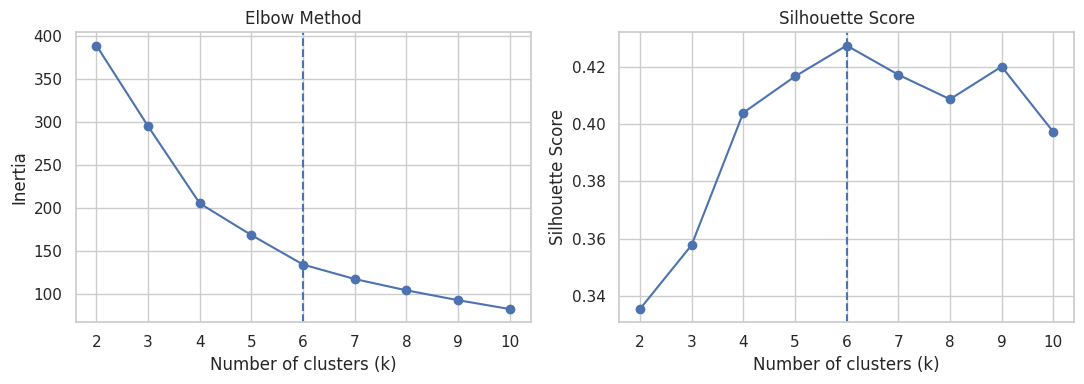

In [36]:
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

k_results = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})

display(k_results)


# Compact model-selection summary
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(k_results["k"], k_results["inertia"], marker="o")
axes[0].axvline(
    best_k if "best_k" in globals() else int(
        k_results.loc[k_results["silhouette_score"].idxmax(), "k"]
    ),
    linestyle="--"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_results["k"], k_results["silhouette_score"], marker="o")
axes[1].axvline(
    best_k if "best_k" in globals() else int(
        k_results.loc[k_results["silhouette_score"].idxmax(), "k"]
    ),
    linestyle="--"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()


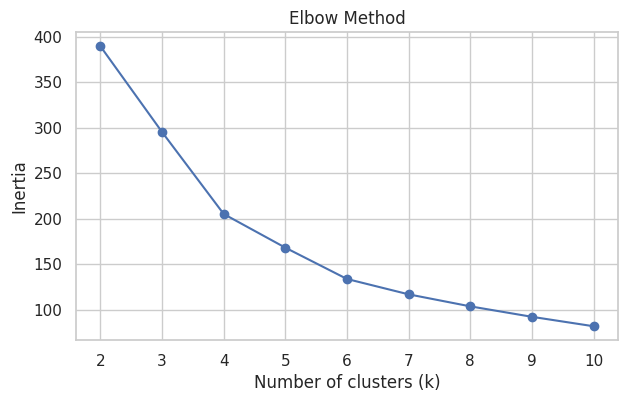

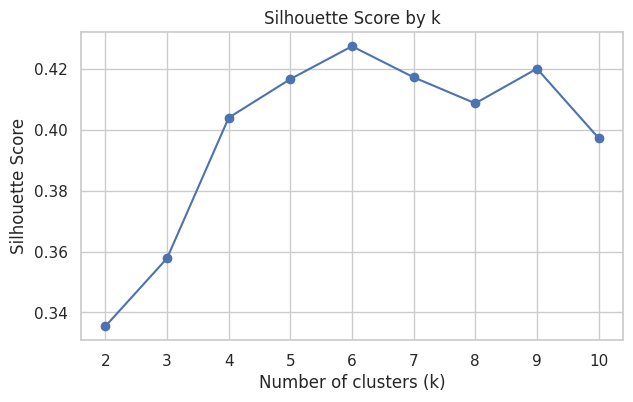

In [37]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_results["k"], k_results["inertia"], marker="o")
ax.set_title("Elbow Method")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    k_results["k"],
    k_results["silhouette_score"],
    marker="o"
)
ax.set_title("Silhouette Score by k")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette Score")
plt.show()


## 7. Fit the final K-Means model

For this notebook, the candidate with the highest silhouette score is used as the starting point for the final clustering.

The silhouette score is a model-selection aid, not proof that one business segmentation is universally correct. The cluster profiles below are therefore just as important as the numerical score.


In [38]:
best_k = int(
    k_results.loc[
        k_results["silhouette_score"].idxmax(),
        "k"
    ]
)

print("Selected k:", best_k)
print(
    "Best silhouette score:",
    round(k_results.loc[
        k_results["k"] == best_k,
        "silhouette_score"
    ].iloc[0], 4)
)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=20
)

clustering_df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nCluster sizes:")
display(
    clustering_df["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("customers")
)


Selected k: 6
Best silhouette score: 0.4274

Cluster sizes:


,customers
Cluster,
0,33
1,45
2,24
3,39
4,38
5,21


## 8. Profile the customer segments

The cluster label itself has no business meaning. I profile each cluster using the original units to understand what makes the groups different.


In [39]:
# Build the final business-facing segment table
cluster_profile = (
    clustering_df
    .groupby("Cluster")[required_columns]
    .mean()
    .round(2)
)

cluster_profile["Customers"] = (
    clustering_df["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_profile["Share (%)"] = (
    cluster_profile["Customers"] / len(clustering_df) * 100
).round(1)

income_median = cluster_profile["Annual Income (k$)"].median()
spending_median = cluster_profile["Spending Score (1-100)"].median()

def segment_label(row):
    high_income = row["Annual Income (k$)"] >= income_median
    high_spending = row["Spending Score (1-100)"] >= spending_median

    if high_income and high_spending:
        return "High-Value Customers"
    if high_income and not high_spending:
        return "High-Income / Lower-Spending"
    if not high_income and high_spending:
        return "Lower-Income / High-Spending"
    return "Lower-Income / Lower-Spending"

cluster_profile["Segment"] = cluster_profile.apply(segment_label, axis=1)

business_view = cluster_profile[
    [
        "Segment",
        "Customers",
        "Share (%)",
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].sort_values("Spending Score (1-100)", ascending=False)

# Final business-facing segment table
display(
    business_view.style.format({
        "Share (%)": "{:.1f}",
        "Age": "{:.1f}",
        "Annual Income (k$)": "{:.1f}",
        "Spending Score (1-100)": "{:.1f}"
    })
)


,Segment,Customers,Share (%),Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,,,
3,High-Value Customers,39,19.5,32.7,86.5,82.1
2,Lower-Income / High-Spending,24,12.0,25.2,25.8,76.9
1,Lower-Income / High-Spending,45,22.5,56.3,54.3,49.1
4,High-Income / Lower-Spending,38,19.0,26.7,57.6,47.8
5,Lower-Income / Lower-Spending,21,10.5,45.5,26.3,19.4
0,High-Income / Lower-Spending,33,16.5,41.9,88.9,17.0


## 9. Compare clusters visually

The following plots use the original feature values. They make it easier to see how income and spending behavior differ between the customer groups.


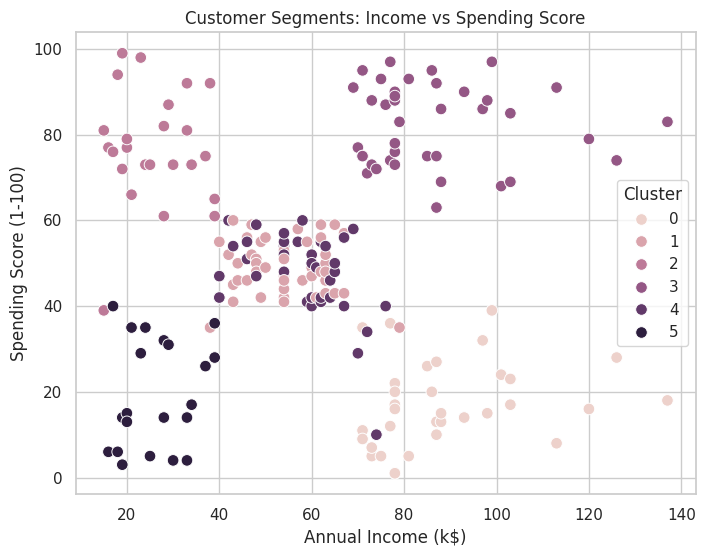

In [40]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=clustering_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    s=70,
    ax=ax
)

ax.set_title("Customer Segments: Income vs Spending Score")
plt.show()


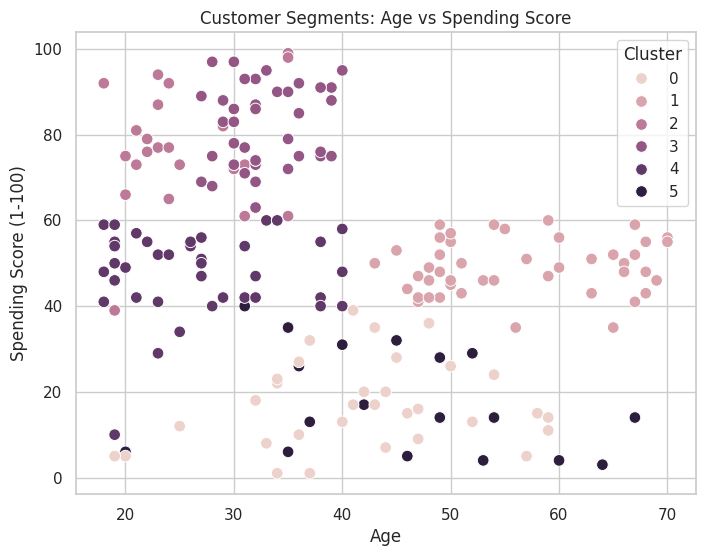

In [41]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=clustering_df,
    x="Age",
    y="Spending Score (1-100)",
    hue="Cluster",
    s=70,
    ax=ax
)

ax.set_title("Customer Segments: Age vs Spending Score")
plt.show()


## 10. PCA visualization

The clustering uses three standardized features. PCA reduces those features to two dimensions only for visualization.

The PCA plot does **not** replace the original clustering or change the model.


Explained variance: [0.443 0.333]


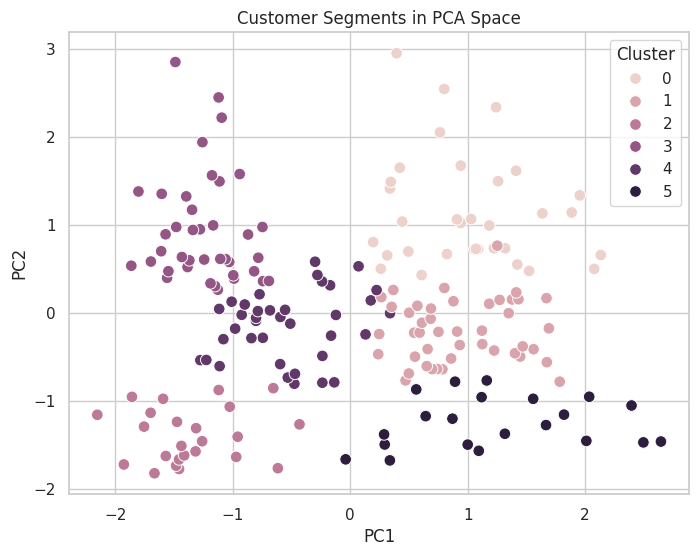

In [42]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": clustering_df["Cluster"].values
})

print(
    "Explained variance:",
    np.round(pca.explained_variance_ratio_, 3)
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    s=70,
    ax=ax
)

ax.set_title("Customer Segments in PCA Space")
plt.show()


## 11. Optional demographic profiling

Gender was not used to create the clusters, but it can be useful when describing the resulting customer groups.

This is descriptive only; it should not be interpreted as evidence that gender caused the clustering.


In [43]:
if "Gender" in clustering_df.columns:
    gender_profile = pd.crosstab(
        clustering_df["Cluster"],
        clustering_df["Gender"],
        normalize="index"
    ).round(3)

    display(gender_profile)
else:
    print("Gender column is not available in this dataset.")


Gender,Female,Male
Cluster,,
0,0.424,0.576
1,0.578,0.422
2,0.583,0.417
3,0.538,0.462
4,0.632,0.368
5,0.619,0.381


## 12. Business interpretation

Cluster numbers are arbitrary, so the business labels are assigned from the observed
cluster profiles rather than from the numeric cluster IDs.

The labels are descriptive summaries of the current dataset:

- **High-Value Customers** — relatively high income and high spending.
- **High-Income / Lower-Spending** — relatively high income but lower spending.
- **Lower-Income / High-Spending** — relatively lower income with higher spending.
- **Lower-Income / Lower-Spending** — relatively lower income and lower spending.

These labels are intended to make the segmentation easier to communicate. They are
not predictions, causal conclusions, or recommendations to target individual customers.


In [44]:
# Create a compact table to make the business interpretation easier.
business_view = cluster_profile[
    [
        "Customers",
        "Share (%)",
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].copy()

display(business_view.sort_values("Spending Score (1-100)", ascending=False))


,Customers,Share (%),Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,,
3,39,19.5,32.69,86.54,82.13
2,24,12.0,25.25,25.83,76.92
1,45,22.5,56.33,54.27,49.07
4,38,19.0,26.68,57.58,47.79
5,21,10.5,45.52,26.29,19.38
0,33,16.5,41.94,88.94,16.97


## 13. Portfolio-ready results

The following outputs are the strongest evidence to present in a project portfolio:

1. Cluster-selection diagnostics (Elbow + Silhouette).
2. Income vs Spending Score segmentation.
3. PCA visualization of the final clusters.
4. Final customer-segment profile table.


In [45]:
# Portfolio-ready clustering summary
# Rebuild the business-facing table from the actual cluster_profile columns.
# This avoids relying on a previously created "Segment" column.

profile = cluster_profile.copy()

profile["Customers"] = (
    clustering_df["Cluster"]
    .value_counts()
    .reindex(profile.index)
    .fillna(0)
    .astype(int)
)

profile["Share (%)"] = (
    profile["Customers"] / len(clustering_df) * 100
).round(1)

income_col = "Annual Income (k$)"
spending_col = "Spending Score (1-100)"

income_median = profile[income_col].median()
spending_median = profile[spending_col].median()

def segment_label(row):
    high_income = row[income_col] >= income_median
    high_spending = row[spending_col] >= spending_median

    if high_income and high_spending:
        return "High-Value Customers"
    elif high_income and not high_spending:
        return "High-Income / Lower-Spending"
    elif not high_income and high_spending:
        return "Lower-Income / High-Spending"
    else:
        return "Lower-Income / Lower-Spending"

profile["Segment"] = profile.apply(segment_label, axis=1)

business_view = profile[
    [
        "Segment",
        "Customers",
        "Share (%)",
        "Age",
        income_col,
        spending_col
    ]
].sort_values(spending_col, ascending=False)

final_silhouette = float(
    k_results.loc[
        k_results["k"] == best_k,
        "silhouette_score"
    ].iloc[0]
)

print("Final Clustering Summary")
print("=" * 50)
print(f"Selected k: {best_k}")
print(f"Best silhouette score: {final_silhouette:.4f}")
print(f"Customers clustered: {len(clustering_df)}")

display(
    business_view.style.format({
        "Share (%)": "{:.1f}",
        "Age": "{:.1f}",
        income_col: "{:.1f}",
        spending_col: "{:.1f}"
    })
)


Final Clustering Summary
Selected k: 6
Best silhouette score: 0.4274
Customers clustered: 200


,Segment,Customers,Share (%),Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,,,
3,High-Value Customers,39,19.5,32.7,86.5,82.1
2,Lower-Income / High-Spending,24,12.0,25.2,25.8,76.9
1,Lower-Income / High-Spending,45,22.5,56.3,54.3,49.1
4,High-Income / Lower-Spending,38,19.0,26.7,57.6,47.8
5,Lower-Income / Lower-Spending,21,10.5,45.5,26.3,19.4
0,High-Income / Lower-Spending,33,16.5,41.9,88.9,17.0


## 14. Final takeaway

This project demonstrates an end-to-end unsupervised learning workflow:

1. Inspect the customer data.
2. Select meaningful clustering features.
3. Standardize the features.
4. Compare several values of `k`.
5. Use inertia and silhouette score to guide model selection.
6. Fit K-Means.
7. Profile the resulting customer groups.
8. Visualize the segments.
9. Translate the clusters into business-oriented observations.

### Limitations

This dataset is small and designed mainly for demonstrating customer segmentation. The resulting groups should not be treated as a production marketing segmentation without validating them on a larger, richer customer dataset and checking whether the segments remain stable over time.

Also, K-Means assumes roughly distance-based cluster structure. Other clustering methods may be useful when the customer groups have different shapes or densities.
